# Import libraries

In [36]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LinearRegression

# Load clean data

Import the data and see the first rows to check if the import is done as expected.

In [37]:
df = pd.read_csv("/Users/jisoo/Desktop/MSDS/26_Fall/DATA5100/education/code/education_clean.csv")
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,housing_price,log_income,log_housing_price,log_unemployment
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,160362.491336,10.664761,11.985192,-2.137389
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,318487.676482,11.399981,12.671339,-2.749115
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,318487.676482,11.340237,12.671339,-2.874223
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,392572.334288,10.941996,12.880476,-3.106921
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,211581.532515,10.897017,12.262366,-2.563774


# Modeling

### Simple Regressoin Models

First, a baseline regression model is constructed using the percentage of students eligible for free or reduced-price lunch to predict school-level ACT scores. Next, five additional socioeconomic variables are evaluated using three functional forms: linear, logarithmic, and quadratic. For each variable, the functional form with the best performance is selected based on the model evaluation results.

In [38]:
# Define the target and predictor variables

target = "average_act"
baseline_var = "percent_lunch"

additional_vars = [
    "rate_unemployment",
    "housing_price",
    "median_income",
    "percent_married",
    "percent_college"
]

# Define the regression models to evaluate
models_to_run = [(baseline_var, "Linear", "Baseline")]

for var in additional_vars:
    for form in ["Linear", "Log", "Quadratic"]:
        models_to_run.append((var, form, "Extended"))

# Fit each model and calculate R² and MAE
results = []

for var, form, model_type in models_to_run:

    if form == "Linear":
        formula = f"{target} ~ {var}"

    elif form == "Log":
        formula = f"{target} ~ np.log({var})"

    elif form == "Quadratic":
        formula = f"{target} ~ {var} + I({var}**2)"

    model = smf.ols(formula=formula, data=df).fit()

    predictions = model.predict(df)

    results.append({
        "Model Type": model_type,
        "Variable": var,
        "Form": form,
        "R²": r2_score(df[target], predictions),
        "MAE": mean_absolute_error(df[target], predictions),
    })

# Sort and display results
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))



,Model Type,Variable,Form,R²,MAE
0,Baseline,percent_lunch,Linear,0.6230,1.1598
1,Extended,median_income,Quadratic,0.2191,1.6972
2,Extended,median_income,Log,0.2128,1.6979
3,Extended,median_income,Linear,0.2112,1.7129
4,Extended,percent_college,Quadratic,0.2102,1.7169
5,Extended,percent_college,Linear,0.2101,1.7169
6,Extended,percent_college,Log,0.2039,1.7241
7,Extended,percent_married,Quadratic,0.1965,1.7347
8,Extended,percent_married,Linear,0.1962,1.7336
9,Extended,rate_unemployment,Quadratic,0.1944,1.7361


Table shows that housing prices perform best with a logarithmic transformation, unemployment and median income with quadratic, and married-couple and college-degree percentages with linear, based on R² and MAE.

This code generates scatter plots with fitted regression curves to compare linear, logarithmic, and quadratic relationships between five socioeconomic variables and average ACT scores. The plots help visualize potential nonlinear patterns and support the selection of the most appropriate functional form for each variable.

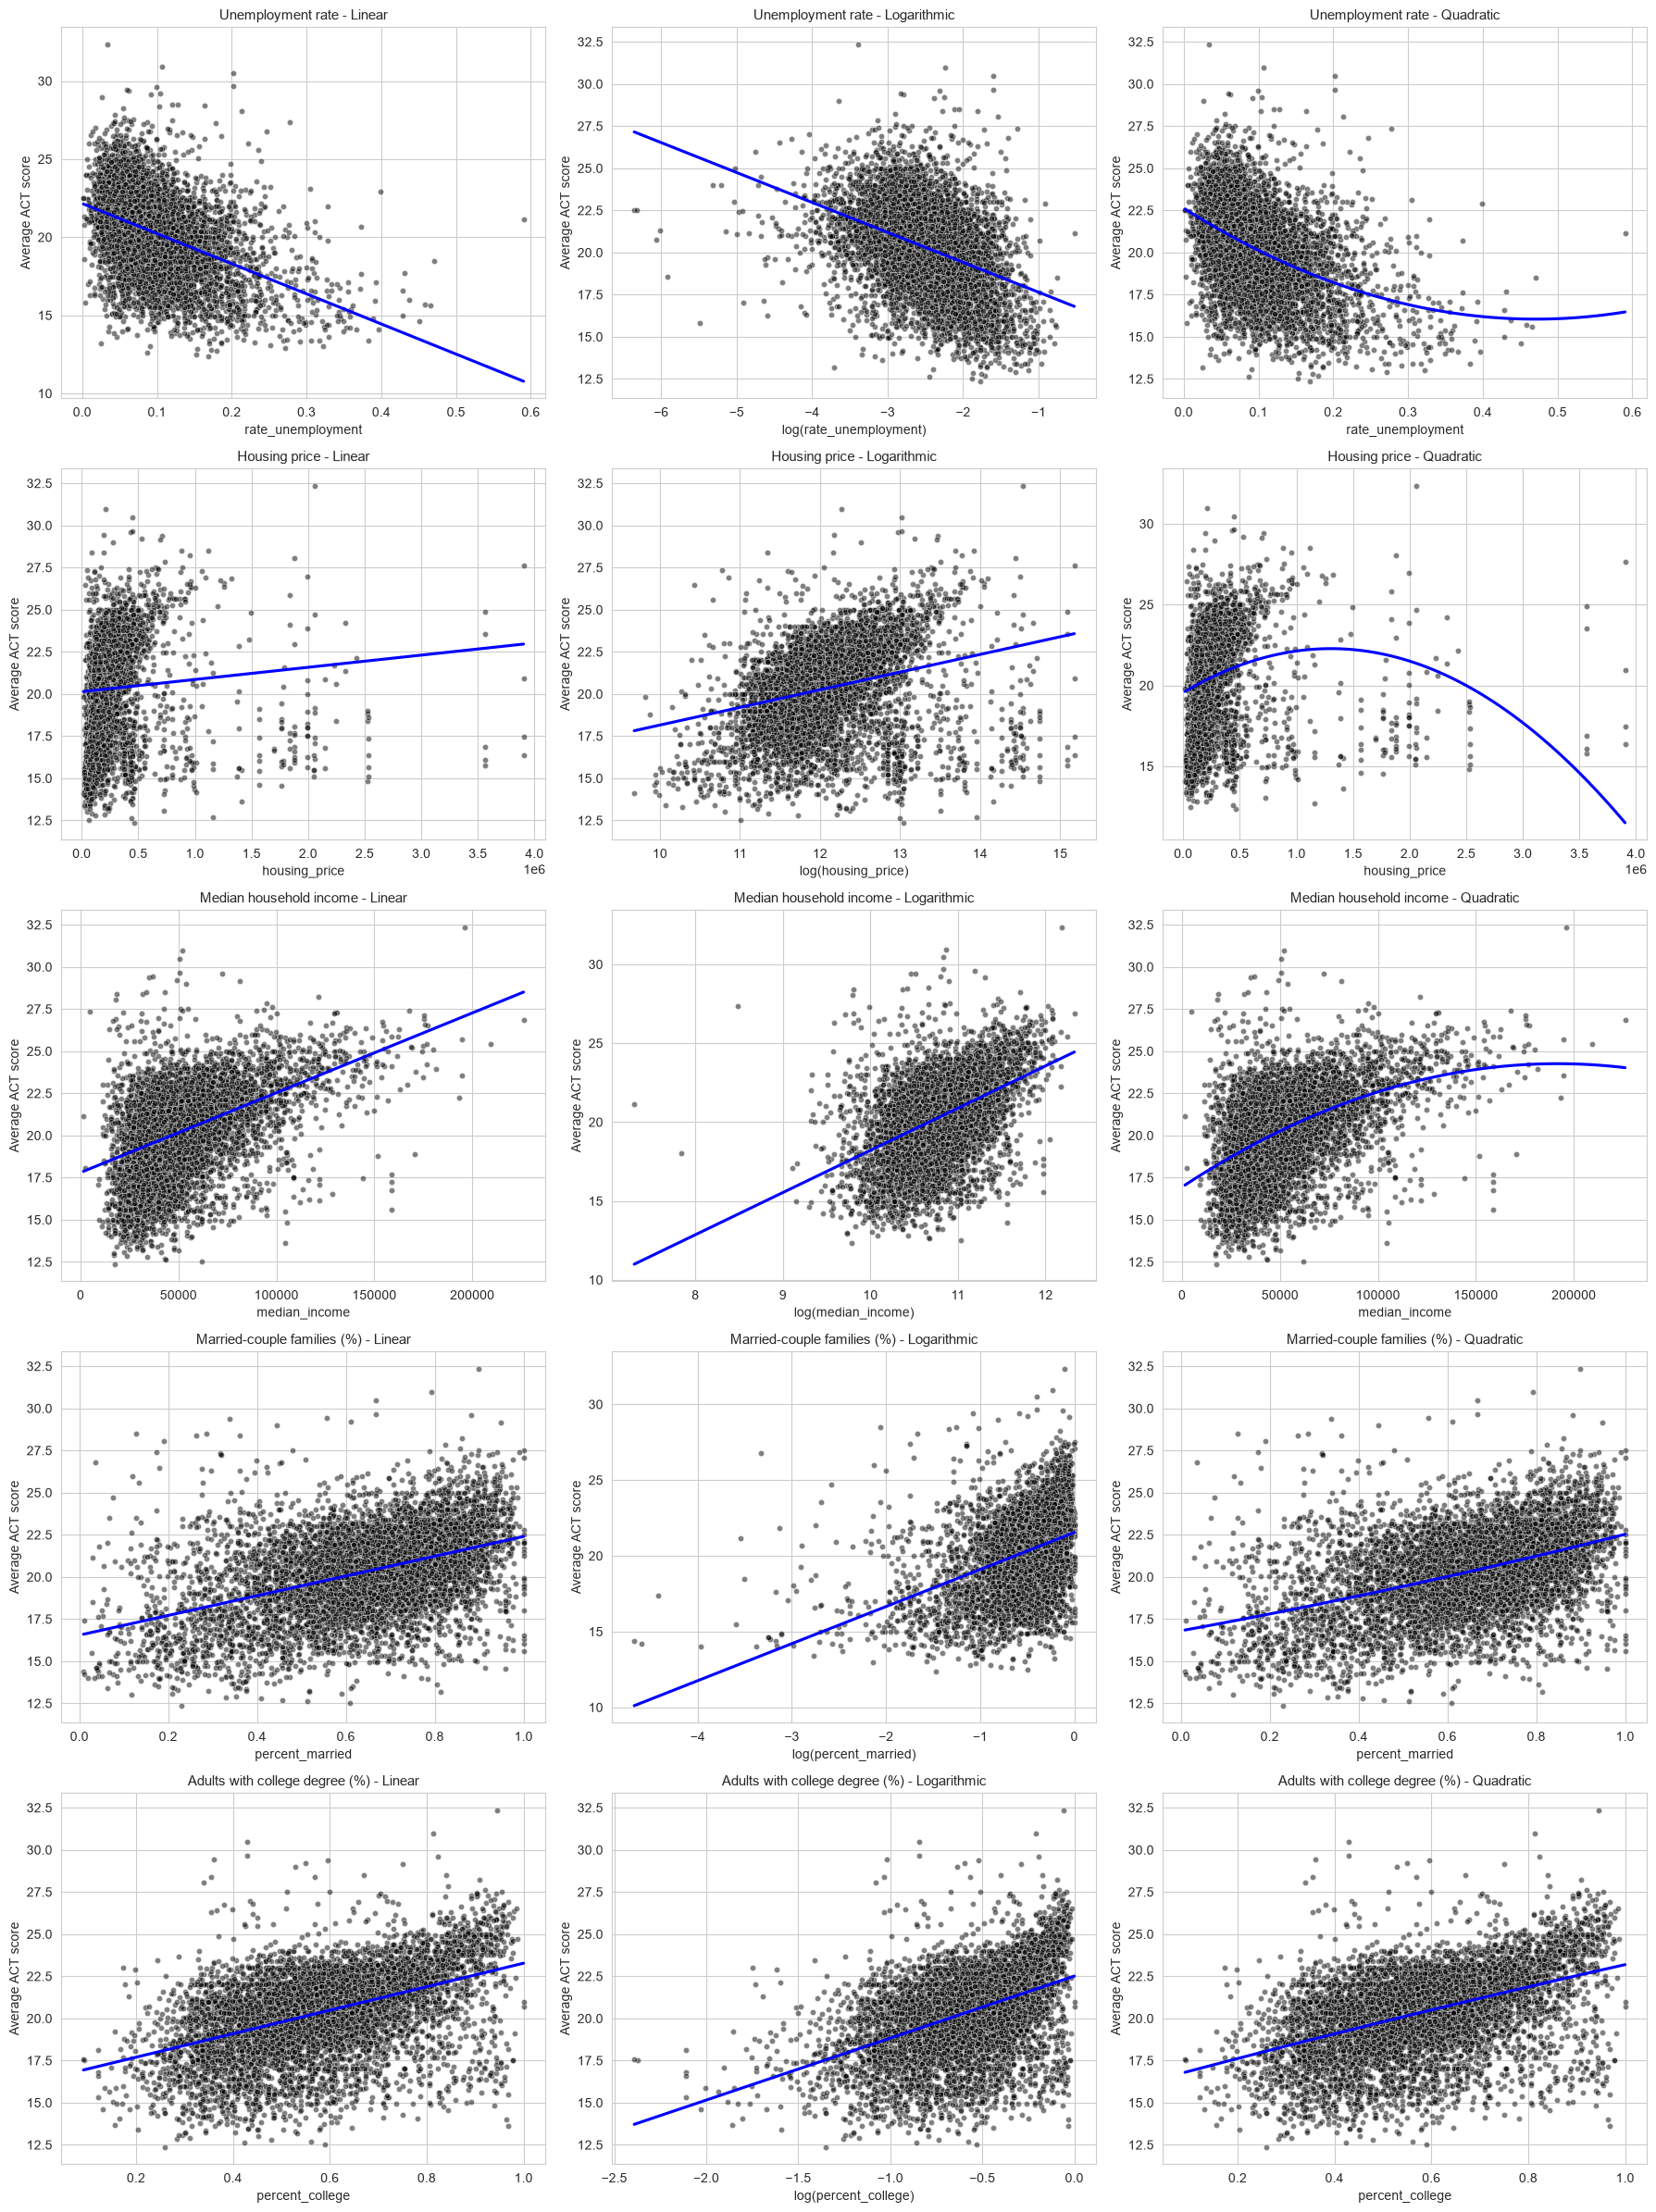

In [39]:

variables = {
    'Unemployment rate': 'rate_unemployment',
    'Housing price': 'housing_price',
    'Median household income': 'median_income',
    'Married-couple families (%)': 'percent_married',
    'Adults with college degree (%)': 'percent_college'
}

fig, axes = plt.subplots(5, 3, figsize=(18, 24))

for row, (label, var) in enumerate(variables.items()):

    # 1. Linear
    ax = axes[row, 0]
    sns.regplot(
        data=df,
        x=var,
        y='average_act',
        ax=ax,
        ci=None,
        color='blue',
        scatter_kws={'color': 'black', 'edgecolors': 'white',
                     'linewidths': 0.5, 'alpha': 0.5, 's': 20},
        line_kws={'color': 'blue'}
    )
    ax.set_title(f'{label} - Linear', fontsize=11)
    ax.set_xlabel(var)
    ax.set_ylabel('Average ACT score')

    # 2. Logarithmic
    ax = axes[row, 1]
    log_var = f'log_{var}'
    df[log_var] = np.log(df[var])

    sns.regplot(
        data=df,
        x=log_var,
        y='average_act',
        ax=ax,
        ci=None,
        color='blue',
        scatter_kws={'color': 'black', 'edgecolors': 'white',
                     'linewidths': 0.5, 'alpha': 0.5, 's': 20},
        line_kws={'color': 'blue'}
    )
    ax.set_title(f'{label} - Logarithmic', fontsize=11)
    ax.set_xlabel(f'log({var})')
    ax.set_ylabel('Average ACT score')

    # 3. Quadratic
    ax = axes[row, 2]
    sns.regplot(
        data=df,
        x=var,
        y='average_act',
        ax=ax,
        order=2,
        ci=None,
        color='blue',
        scatter_kws={'color': 'black', 'edgecolors': 'white',
                     'linewidths': 0.5, 'alpha': 0.5, 's': 20},
        line_kws={'color': 'blue'}
    )
    ax.set_title(f'{label} - Quadratic', fontsize=11)
    ax.set_xlabel(var)
    ax.set_ylabel('Average ACT score')

plt.tight_layout()
plt.show()


The graphs generally support the numerical model evaluation results. Because housing prices have large values, the linear and quadratic plots appear heavily skewed to the left, while the logarithmic transformation provides a clearer visualization of the relationship with ACT scores.

This code selects the transformed model which has better MAE or R square than linear model.

In [40]:

# Compare transformed models with the linear model for each variable
for var in additional_vars:
    var_results = results_df[results_df["Variable"] == var]

    linear_result = var_results[var_results["Form"] == "Linear"].iloc[0]
    transformed_results = var_results[var_results["Form"].isin(["Log", "Quadratic"])]

    better_models = transformed_results[
        (transformed_results["R²"] > linear_result["R²"]) &
        (transformed_results["MAE"] < linear_result["MAE"])
    ]

    print(f"\nVariable: {var}")
    print(f"Linear R²: {linear_result['R²']:.4f} | "
          f"Linear MAE: {linear_result['MAE']:.4f}")

    if better_models.empty:
        print("No transformed model outperformed the linear model on both metrics.")
    else:
        print("Transformed models that outperformed the linear model:")
        display(
            better_models[
                ["Form", "R²", "MAE"]
            ].sort_values("R²", ascending=False).round(4)
        )



Variable: rate_unemployment
Linear R²: 0.1885 | Linear MAE: 1.7406
Transformed models that outperformed the linear model:


,Form,R²,MAE
9,Quadratic,0.1944,1.7361



Variable: housing_price
Linear R²: 0.0062 | Linear MAE: 1.9579
Transformed models that outperformed the linear model:


,Form,R²,MAE
13,Log,0.0756,1.8624
14,Quadratic,0.0444,1.9027



Variable: median_income
Linear R²: 0.2112 | Linear MAE: 1.7129
Transformed models that outperformed the linear model:


,Form,R²,MAE
1,Quadratic,0.2191,1.6972
2,Log,0.2128,1.6979



Variable: percent_married
Linear R²: 0.1962 | Linear MAE: 1.7336
No transformed model outperformed the linear model on both metrics.

Variable: percent_college
Linear R²: 0.2101 | Linear MAE: 1.7169
Transformed models that outperformed the linear model:


,Form,R²,MAE
4,Quadratic,0.2102,1.7169


Based on these results, we selected the optimal functional form for each variable—quadratic for rate_unemployment, log for housing_price, quadratic for median_income, linear for percent_married as these configurations yielded the highest $R^2$ and lowest MAE compared to alternative forms. For the percentage of adults with a college degree, we selected the linear form because the quadratic model showed no meaningful improvement in MAE. Given the similar performance, we chose the simpler model for efficiency.

### Multipe Regression Models

Each selected variable is then added individually to the baseline model to construct an extended model. The baseline and extended models are evaluated using the R² and MAE. An extended model is considered to improve predictive performance only if it achieves both a higher  and a lower MAE than the baseline model. If only one metric improves, the extended model is not considered better under this criterion.

In [41]:
# Define the target and baseline predictor
target = "average_act"
baseline_var = "percent_lunch"

# Define the selected functional form for each additional variable
selected_forms = {
    "rate_unemployment": "Quadratic",
    "housing_price": "Log",
    "median_income": "Quadratic",
    "percent_married": "Linear",
    "percent_college": "Linear"
}

# Define the baseline model
baseline_formula = f"{target} ~ {baseline_var}"
baseline_model = smf.ols(baseline_formula, data=df).fit()
baseline_predictions = baseline_model.predict(df)

results = [{
    "Model": "Baseline",
    "Added Variable": "None",
    "Functional Form": "Linear",
    "R²": r2_score(df[target], baseline_predictions),
    "MAE": mean_absolute_error(df[target], baseline_predictions),
    "Adjusted R²": baseline_model.rsquared_adj
}]

# Fit each extended model and evaluate its performance
for var, form in selected_forms.items():

    if form == "Linear":
        formula = f"{target} ~ {baseline_var} + {var}"

    elif form == "Log":
        formula = f"{target} ~ {baseline_var} + np.log({var})"

    elif form == "Quadratic":
        formula = (
            f"{target} ~ {baseline_var} + {var} + I({var}**2)"
        )

    model = smf.ols(formula=formula, data=df).fit()
    predictions = model.predict(df)

    results.append({
        "Model": "Extended",
        "Added Variable": var,
        "Functional Form": form,
        "R²": r2_score(df[target], predictions),
        "MAE": mean_absolute_error(df[target], predictions),
        "Adjusted R²": model.rsquared_adj
    })

# Display and compare model performance
results_df = pd.DataFrame(results)

baseline_r2 = results_df.loc[0, "R²"]
baseline_mae = results_df.loc[0, "MAE"]

results_df["Change in R²"] = results_df["R²"] - baseline_r2
results_df["Change in MAE"] = results_df["MAE"] - baseline_mae

display(results_df.round(4))


,Model,Added Variable,Functional Form,R²,MAE,Adjusted R²,Change in R²,Change in MAE
0,Baseline,None,Linear,0.6230,1.1598,0.6230,0.0000,0.0000
1,Extended,rate_unemployment,Quadratic,0.6270,1.1528,0.6268,0.0040,-0.0071
2,Extended,housing_price,Log,0.6327,1.1433,0.6326,0.0097,-0.0165
3,Extended,median_income,Quadratic,0.6323,1.1448,0.6322,0.0093,-0.0151
4,Extended,percent_married,Linear,0.6242,1.1579,0.6241,0.0012,-0.0019
5,Extended,percent_college,Linear,0.6332,1.1419,0.6331,0.0102,-0.0180


Table indicates that the multiple regression model incorporating the percent lunch variable and the linear term for the percentage of adults with a college degree achieves the best performance among the initial extended models, based on R^2 and MAE.

Scatter plots and regression curves are examined to visualize the relationships between the socioeconomic variables and ACT scores and to identify potential opportunities for model improvement. 

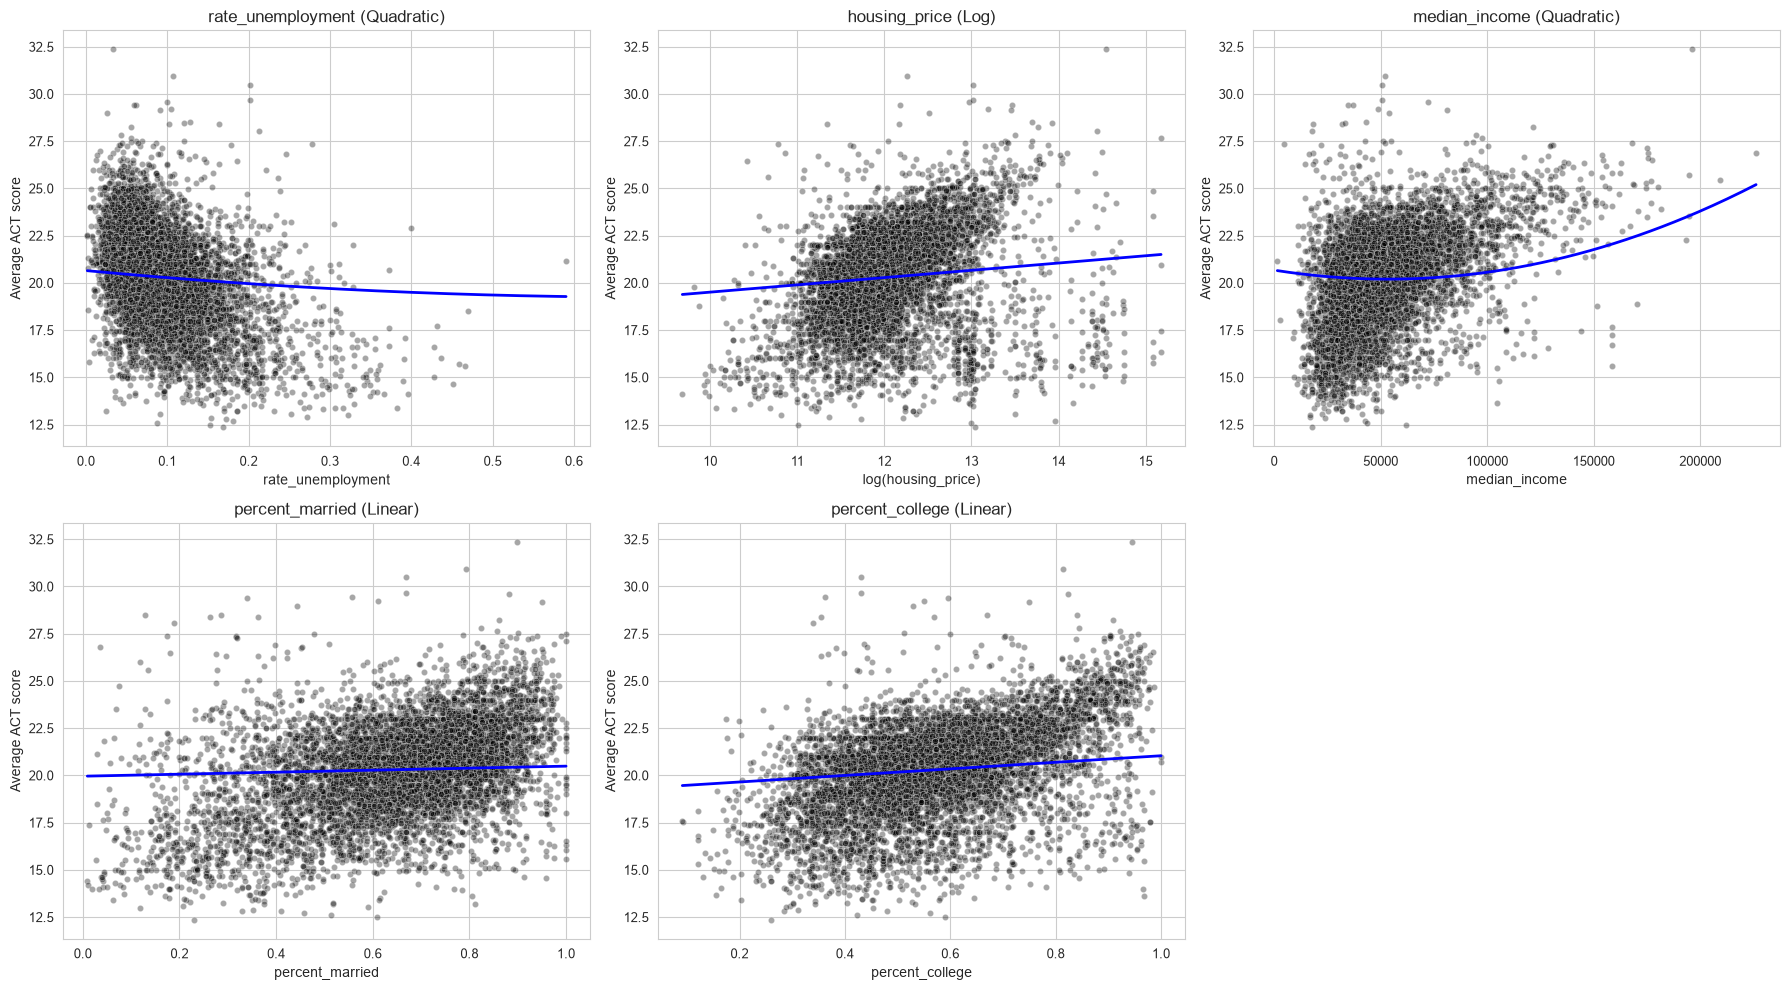

In [42]:
selected_forms = {
    "rate_unemployment": "Quadratic",
    "housing_price": "Log",
    "median_income": "Quadratic",
    "percent_married": "Linear",
    "percent_college": "Linear"
}

target = "average_act"
baseline_var = "percent_lunch"

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (var, form) in enumerate(selected_forms.items()):
    ax = axes[i]
    
    # 1. Fit the OLS model based on the selected functional form
    if form == "Linear":
        formula = f"{target} ~ {baseline_var} + {var}"
    elif form == "Log":
        formula = f"{target} ~ {baseline_var} + np.log({var})"
    elif form == "Quadratic":
        formula = f"{target} ~ {baseline_var} + {var} + I({var}**2)"

    model = smf.ols(formula=formula, data=df).fit()

    # 2. Set scatter plot data and x-axis label (apply log transformation for Log form)
    if form == "Log":
        x_plot_data = np.log(df[var])
        x_label_str = f"log({var})"
    else:
        x_plot_data = df[var]
        x_label_str = var

    ax.scatter(
        x_plot_data, df[target],
        color="black", edgecolors="white",
        linewidths=0.5, alpha=0.35, s=20
    )

    # 3. Generate prediction grid and corresponding x-values
    if form == "Log":
        x_grid_log = np.linspace(np.log(df[var]).min(), np.log(df[var]).max(), 200)
        x_grid = np.exp(x_grid_log) # Restore original units for model prediction
    else:
        x_grid = np.linspace(df[var].min(), df[var].max(), 200)

    # Hold the baseline predictor at its mean for prediction
    pred_df = pd.DataFrame({
        baseline_var: df[baseline_var].mean(),
        var: x_grid
    })

    # Predict using the fitted model
    y_pred = model.predict(pred_df)

    # 4. Plot the regression line (match log-scale coordinates if form is Log)
    if form == "Log":
        ax.plot(x_grid_log, y_pred, color="blue", linewidth=2)
    else:
        ax.plot(x_grid, y_pred, color="blue", linewidth=2)

    ax.set_title(f"{var} ({form})", fontsize=12)
    ax.set_xlabel(x_label_str, fontsize=10)
    ax.set_ylabel("Average ACT score", fontsize=10)
    ax.tick_params(labelsize=9)

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Graph shows a potential nonlinear pattern in the observed data. 

To investigate whether this pattern can be better captured, a quadratic term for the percentage of adults with a college degree is added to the multiple regression model.

In [45]:
final_model = smf.ols(
    formula = 'average_act ~ percent_college + I(percent_college**2) + percent_lunch ',
    data = df).fit()
print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.641
Method:                 Least Squares   F-statistic:                     4292.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:49:55   Log-Likelihood:                -13202.
No. Observations:                7227   AIC:                         2.641e+04
Df Residuals:                    7223   BIC:                         2.644e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

The resulting model achieves an R^2 of 0.641, outperforming the baseline simple linear regression model using only the percent_lunch variable. These results suggest that incorporating the quadratic relationship between college attainment and ACT scores may improve the model's ability to explain variation in school-level ACT scores.

Now draw a regression plot and residual plot to visualize the findings.

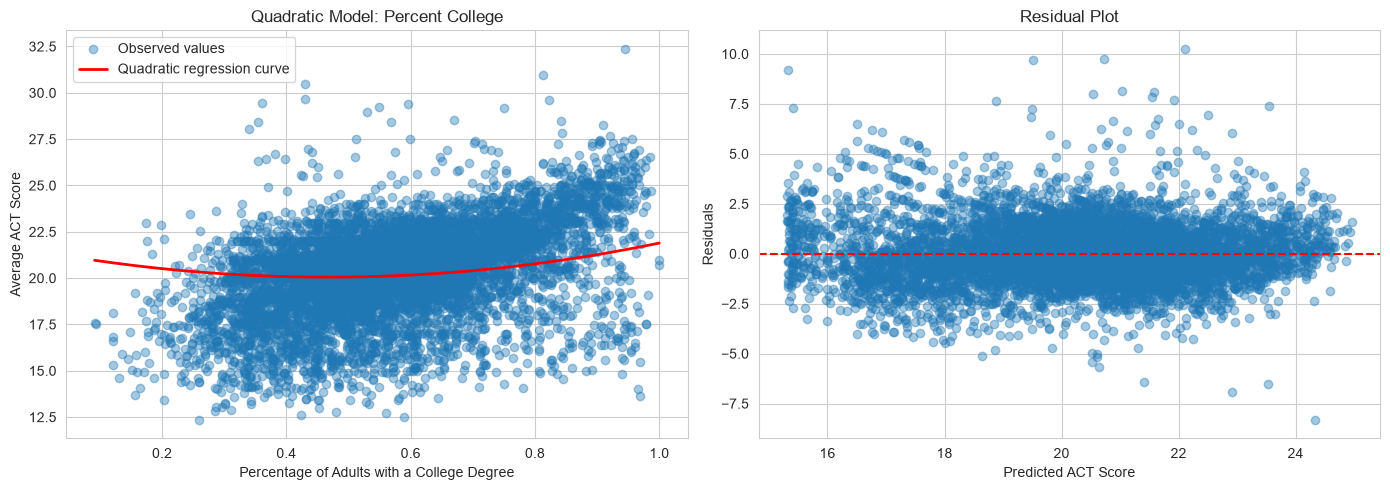

R²: 0.6407
MAE: 1.1245


In [44]:

# 1. Fit the quadratic regression model
model = smf.ols(
    formula='average_act ~ percent_lunch + percent_college + I(percent_college**2)',
    data=df
).fit()

# 2. Generate predictions for the regression curve
x_grid = np.linspace(
    df['percent_college'].min(),
    df['percent_college'].max(),
    200
)

prediction_df = pd.DataFrame({
    'percent_college': x_grid,
    'percent_lunch': df['percent_lunch'].mean()
})

y_pred = model.predict(prediction_df)

# 3. Calculate predicted values and residuals for all observations
y_pred_all = model.predict(df)
residuals = df['average_act'] - y_pred_all

# 4. Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Scatter plot + quadratic regression curve
axes[0].scatter(
    df['percent_college'],
    df['average_act'],
    alpha=0.4,
    label='Observed values'
)

axes[0].plot(
    x_grid,
    y_pred,
    linewidth=2,
    color="red",
    label='Quadratic regression curve'
)

axes[0].set_xlabel('Percentage of Adults with a College Degree')
axes[0].set_ylabel('Average ACT Score')
axes[0].set_title('Quadratic Model: Percent College')
axes[0].legend()

# Right: Residual plot
axes[1].scatter(
    y_pred_all,
    residuals,
    alpha=0.4
)

axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted ACT Score')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

# 5. Model evaluation
print(f"R²: {model.rsquared:.4f}")
print(f"MAE: {np.mean(np.abs(residuals)):.4f}")

The residuals are centered around zero across the range of predicted ACT scores, with no clear curved pattern, which suggests that the quadratic specification captures the main nonlinear relationship reasonably well.

Therefore the final model can be written as below

$$
\widehat{ACT} = 24.8068 - 8.1035L - 6.0446C + 6.4753C^2
$$

where \(L\) is the percentage of students eligible for free or reduced-price lunch, and \(C\) is the percentage of adults with a college degree.